# Fine-Tuning IndoBART + LoRA *Two-Step Fine-Tuning*

**Model dasar** : `indobenchmark/indobart-v2`  
**Teknik** : Low-Rank Adaptation (LoRA) via `peft`  
**Task** : Peringkasan Berita  
**Dataset** : Liputan6 dan berita BPS Provinsi DKI Jakarta  

## 1. Instalasi Library

In [ ]:
!pip install transformers datasets peft accelerate scikit-learn pandas openpyxl evaluate rouge_score sentencepiece -q
!pip install torchao --upgrade -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 45.4 MB/s eta 0:00:00


## 2. Import Library

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import torch
import evaluate

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model,
    PeftModel,
)

# Cek GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


## 3. Konfigurasi Global

In [ ]:
# model
MODEL_NAME        = 'indobenchmark/indobart-v2'

# panjang token
MAX_INPUT_LENGTH  = 512   # artikel input
MAX_TARGET_LENGTH = 128   # ringkasan output

# jumlah data Liputan6
N_LIPUTAN6_TRAIN  = 193883
N_LIPUTAN6_VAL    = 10972
N_LIPUTAN6_TEST   = 10972

# output
STEP1_OUTPUT_DIR  = './indobart-lora-step1-liputan6'
STEP1_MERGED_DIR  = './indobart-merged-step1-liputan6'
STEP2_OUTPUT_DIR  = './indobart-lora-step2-bps'
STEP2_MERGED_DIR  = './indobart-merged-step2-bps'

print('Konfigurasi global berhasil dimuat.')

Konfigurasi global berhasil dimuat.


## 4. Load Tokenizer

In [ ]:
from transformers import MBartTokenizer

tokenizer = MBartTokenizer.from_pretrained(MODEL_NAME)

print('Tokenizer loaded:', MODEL_NAME)
print('Vocab size       :', tokenizer.vocab_size)
print('pad_token_id     :', tokenizer.pad_token_id)

tokenizer_config.json:   0%|          | 0.00/303 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  932kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Tokenizer loaded: indobenchmark/indobart
Vocab size       : 40027
pad_token_id     : 1


## 5. Fungsi Preprocessing & Tokenisasi

In [ ]:
def clean_text(text):
    """Membersihkan teks."""
    # handle format Liputan6 (list of list of tokens)
    if isinstance(text, list) and len(text) > 0 and isinstance(text[0], list):
        text = ' '.join([' '.join(sent) for sent in text])
    elif isinstance(text, list):
        text = ' '.join(text)

    # hapus kata Liputan6,com di awal kalimat
    text = re.sub(r'^liputan6\s*[\.,]\s*com\s*,\s*[a-zA-Z\s]+\s*[:\-]\s*', '', text, flags=re.IGNORECASE)

    # hapus author tags
    text = re.sub(r'\s*\([^)]+\)\s*\.?\s*$', '', text)
    text = re.sub(r'\s*\([^)]+/[^)]+\)\s*', ' ', text)
    text = re.sub(r'\s*\([^)]*(liputan\s*6|sctv|idn\s*times|antara|foto)[^)]*\)\s*', ' ', text, flags=re.IGNORECASE)

    # hapus keterangan gambar/tabel
    text = re.sub(r'^Ilustrasi[^)]+\)\s*', '', text, flags=re.IGNORECASE)

    text = text.lower()

    if not isinstance(text, str):
        return ''

    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^\w\s.,!?;:\-\'\"()%]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def tokenize_fn(examples, input_col, target_col):
    inputs  = [clean_text(t) for t in examples[input_col]]
    targets = [clean_text(t) for t in examples[target_col]]

    model_inputs = tokenizer(
        inputs,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        padding=False,
    )

    labels = tokenizer(
        text_target=targets,
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
        padding=False,
    )

    model_inputs['labels'] = labels['input_ids']
    return model_inputs

print('Fungsi preprocessing & tokenisasi siap.')

Fungsi preprocessing & tokenisasi siap.


## 6. Metrik Evaluasi ROUGE

In [ ]:
rouge = evaluate.load('rouge')
bleu  = evaluate.load('bleu')

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.clip(predictions, 0, tokenizer.vocab_size - 1)
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)

    # ganti -100 pada labels dengan pad_token_id sebelum decode
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds  = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    # hitung ROUGE
    result = rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=False,
    )

    # hitung BLEU
    result_bleu = bleu.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels],
    )

    return {
        'rouge1': round(result['rouge1'], 4),
        'rouge2': round(result['rouge2'], 4),
        'rougeL': round(result['rougeL'], 4),
        'bleu'   : round(result_bleu['bleu'], 4),
    }


print('Metrik ROUGE siap.')

Metrik ROUGE siap.


## 7. Konfigurasi LoRA

In [ ]:
# Konfigurasi LoRA untuk BART
lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,       # sequence-to-sequence
    r=16,                                  # rank LoRA
    lora_alpha=32,                         # alpha
    target_modules=['q_proj', 'v_proj'],   # modul attention BART
    lora_dropout=0.1,                      # dropout untuk regularisasi
    bias='none',                           # tidak melatih bias
    inference_mode=False                   # bukan mode inferensi
)

print('Konfigurasi LoRA siap.')
print(f'  rank (r)       : {lora_config.r}')
print(f'  lora_alpha     : {lora_config.lora_alpha}')
print(f'  target_modules : {lora_config.target_modules}')

Konfigurasi LoRA siap.
  rank (r)       : 16
  lora_alpha     : 32
  target_modules : {'q_proj', 'v_proj'}


---
# STEP 1 — Fine-Tuning dengan Dataset Liputan6

## 8. Load & Persiapan Dataset Liputan6

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import zipfile
from pathlib import Path
from datasets import load_dataset

DRIVE_DIR  = '/content/drive/MyDrive/Skripsi/Dataset/liputan6_data'
LOCAL_DIR  = '/content/liputan6'

zips = {
    f'{DRIVE_DIR}/canonical/canonical_train.zip' : f'{LOCAL_DIR}/canonical/train',
    f'{DRIVE_DIR}/canonical/canonical_dev.zip'   : f'{LOCAL_DIR}/canonical/dev',
    f'{DRIVE_DIR}/canonical/canonical_test.zip'  : f'{LOCAL_DIR}/canonical/test',
    f'{DRIVE_DIR}/xtreme/xtreme_dev.zip'         : f'{LOCAL_DIR}/xtreme/dev',
    f'{DRIVE_DIR}/xtreme/xtreme_test.zip'        : f'{LOCAL_DIR}/xtreme/test',
}

print('=== Extract ZIP ===\n')
for zip_path, extract_dir in zips.items():
    zip_name = os.path.basename(zip_path)
    if not os.path.exists(zip_path):
        print(f'✗ {zip_name} — tidak ditemukan, skip.')
        continue
    os.makedirs(extract_dir, exist_ok=True)
    print(f'Mengextract {zip_name}...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_dir)
    actual = len([f for f in os.listdir(extract_dir) if f.endswith('.json')])
    print(f'  ✓ {actual:,} file terekstrak ke {extract_dir}\n')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Extract ZIP ===

Mengextract canonical_train.zip...
  ✓ 193,883 file terekstrak ke /content/liputan6/canonical/train

Mengextract canonical_dev.zip...
  ✓ 10,972 file terekstrak ke /content/liputan6/canonical/dev

Mengextract canonical_test.zip...
  ✓ 10,972 file terekstrak ke /content/liputan6/canonical/test

Mengextract xtreme_dev.zip...
  ✓ 4,948 file terekstrak ke /content/liputan6/xtreme/dev

Mengextract xtreme_test.zip...
  ✓ 3,862 file terekstrak ke /content/liputan6/xtreme/test



In [ ]:
splits_expected = {
    'canonical/train': 193883,
    'canonical/dev'  : 10972,
    'canonical/test' : 10972,
    'xtreme/dev'     : 4948,
    'xtreme/test'    : 3862,
}

print('=== Merge JSON → JSONL ===\n')
for split, expected in splits_expected.items():
    folder      = f'{LOCAL_DIR}/{split}'
    output_path = f'{LOCAL_DIR}/{split}.jsonl'

    if not os.path.exists(folder):
        print(f'✗ {split} — folder tidak ditemukan, skip.')
        continue

    files = sorted(Path(folder).glob('*.json'))
    print(f'Menggabungkan {len(files):,} file → {split}.jsonl ...')

    with open(output_path, 'w', encoding='utf-8') as out:
        for f in files:
            with open(f, 'r', encoding='utf-8') as inp:
                data = json.load(inp)
                out.write(json.dumps(data, ensure_ascii=False) + '\n')

    actual = sum(1 for _ in open(output_path, encoding='utf-8'))
    status = '✓' if actual == expected else '✗'
    print(f'  {status} {actual:,} / {expected:,} baris\n')

=== Merge JSON → JSONL ===

Menggabungkan 193,883 file → canonical/train.jsonl ...
  ✓ 193,883 / 193,883 baris

Menggabungkan 10,972 file → canonical/dev.jsonl ...
  ✓ 10,972 / 10,972 baris

Menggabungkan 10,972 file → canonical/test.jsonl ...
  ✓ 10,972 / 10,972 baris

Menggabungkan 4,948 file → xtreme/dev.jsonl ...
  ✓ 4,948 / 4,948 baris

Menggabungkan 3,862 file → xtreme/test.jsonl ...
  ✓ 3,862 / 3,862 baris



In [ ]:
print('=== Load Dataset ===\n')
liputan6_raw = load_dataset(
    'json',
    data_files={
        'train'     : f'{LOCAL_DIR}/canonical/train.jsonl',
        'validation': f'{LOCAL_DIR}/canonical/dev.jsonl',
        'test'      : f'{LOCAL_DIR}/canonical/test.jsonl',
    }
)

print('Struktur dataset:')
print(liputan6_raw)
print('\nKolom:', liputan6_raw['train'].column_names)

=== Load Dataset ===



Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Struktur dataset:
DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 193883
    })
    validation: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 10972
    })
    test: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 10972
    })
})

Kolom: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary']


In [ ]:
INPUT_COL_L6  = 'clean_article'
TARGET_COL_L6 = 'clean_summary'

train_l6 = liputan6_raw['train'].shuffle(seed=42).select(range(N_LIPUTAN6_TRAIN))
val_l6   = liputan6_raw['validation'].shuffle(seed=42).select(range(N_LIPUTAN6_VAL))
test_l6  = liputan6_raw['test'].shuffle(seed=42).select(range(N_LIPUTAN6_TEST))

print(f'Train Liputan6 : {len(train_l6)} data')
print(f'Val Liputan6   : {len(val_l6)} data')

def liputan6_to_str(x):
    """Ubah list of list of tokens → string."""
    if isinstance(x, list) and len(x) > 0 and isinstance(x[0], list):
        return ' '.join([' '.join(sent) for sent in x])
    elif isinstance(x, list):
        return ' '.join(x)
    return x

sample_lens = [len(liputan6_to_str(x).split()) for x in train_l6[INPUT_COL_L6][:500]]
print(f'\nRata-rata panjang artikel   : {np.mean(sample_lens):.0f} kata')
print(f'Rata-rata panjang ringkasan : {np.mean([len(liputan6_to_str(x).split()) for x in train_l6[TARGET_COL_L6][:500]]):.0f} kata')

# print contoh artikel
sample_artikel   = train_l6[5][INPUT_COL_L6]
sample_ringkasan = train_l6[5][TARGET_COL_L6]
print('\n[Artikel]:')
print(sample_artikel)
print('\n[Ringkasan Referensi]:')
print(sample_ringkasan)
print('\n[Clean Article]')
print(clean_text(sample_artikel))

Train Liputan6 : 193883 data
Val Liputan6   : 10972 data

Rata-rata panjang artikel   : 223 kata
Rata-rata panjang ringkasan : 31 kata

[Artikel]:
[['Liputan6', '.', 'com', ',', 'Bojonegoro', ':', 'Rencana', 'pemerintah', 'untuk', 'mengimpor', 'beras', 'terus', 'menuai', 'protes', 'di', 'beberapa', 'daerah', '.'], ['Di', 'Bojonegoro', ',', 'Jawa', 'Timur', ',', 'sebanyak', '70', 'perwakilan', 'petani', 'menyatakan', 'penolakannya', 'saat', 'mengikuti', 'sosialisasi', 'unit', 'produksi', 'gabah', 'dan', 'beras', 'belum', 'lama', 'ini', '.'], ['Mereka', 'meminta', 'agar', 'pemerintah', 'mengurungkan', 'niat', 'tersebut', 'karena', 'akan', 'menyebabkan', 'harga', 'gabah', 'dan', 'beras', 'lokal', 'anjlok', '.', 'Sementara', 'di', 'Semarang', ',', 'Jawa', 'Tengah', ',', 'para', 'petani', 'menyambut', 'baik', 'keputusan', 'Gubernur', 'Mardiyanto', 'yang', 'menolak', 'kebijakan', 'impor', 'beras', '.'], ['Pasalnya', 'produksi', 'beras', 'di', 'Jateng', 'tahun', 'ini', 'mencapai', '11', 'juta

In [ ]:
def tokenize_l6(examples):
    return tokenize_fn(examples, INPUT_COL_L6, TARGET_COL_L6)

cols_to_remove = train_l6.column_names

train_l6_tok = train_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)
val_l6_tok   = val_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)
test_l6_tok  = test_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)

print('Tokenisasi Liputan6 selesai.')
print('Contoh panjang input:', len(train_l6_tok[0]['input_ids']))
print('Contoh panjang label:', len(train_l6_tok[0]['labels']))

Map:   0%|          | 0/193883 [00:00<?, ? examples/s]

Map:   0%|          | 0/10972 [00:00<?, ? examples/s]

Map:   0%|          | 0/10972 [00:00<?, ? examples/s]

Tokenisasi Liputan6 selesai.
Contoh panjang input: 477
Contoh panjang label: 75


## 9. Load Model & Terapkan LoRA (Step 1)

In [ ]:
print('Memuat base model IndoBART...')
base_model_s1 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

base_model_s1.resize_token_embeddings(len(tokenizer))
print(f'Embedding diresizing: 40004 → {len(tokenizer)}')
base_model_s1.config.decoder_start_token_id = tokenizer.eos_token_id

base_model_s1.config.use_cache = False

# terapkan LoRA
model_s1 = get_peft_model(base_model_s1, lora_config)
model_s1.enable_input_require_grads()
model_s1.print_trainable_parameters()

Memuat base model IndoBART...


config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  526MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/267 [00:00<?, ?it/s]

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


model.safetensors: reconstructing file:   0%|          |  0.00B /  526MB            

model.safetensors: downloading bytes:           |  0.00B            

Embedding diresizing: 40004 → 40026
trainable params: 884,736 || all params: 132,444,672 || trainable%: 0.6680


/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:78: UserWarning: The PEFT config's `base_model_name_or_path` was renamed from '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/./indobart-merged-step1-liputan6' to 'indobenchmark/indobart'. Please ensure that the correct base model is loaded when loading this checkpoint.
  warnings.warn(


## 10. Training Step 1 — Liputan6

In [ ]:
data_collator_s1 = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model_s1,
    padding=True,           # padding dengan data collator
    pad_to_multiple_of=8,   # kelipatan 8
    label_pad_token_id=-100,
)

training_args_s1 = Seq2SeqTrainingArguments(
    output_dir="/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART",

    save_strategy="epoch",
    save_steps=1,
    save_total_limit=3,
    eval_strategy='epoch',
    eval_steps=1,

    num_train_epochs=50,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=1e-5,

    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,               # generasi
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=4,

    fp16=True,
    seed=42,
    report_to='none',
)

trainer_s1 = Seq2SeqTrainer(
    model=model_s1,
    args=training_args_s1,
    train_dataset=train_l6_tok,
    eval_dataset=val_l6_tok,
    processing_class=tokenizer,
    data_collator=data_collator_s1,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)], # in 5 epoch
)

print('Trainer Step 1 siap. Memulai training...')


Trainer Step 1 siap. Memulai training...


In [ ]:
result_s1 = trainer_s1.train()
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
1,1.989771,2.539095,0.272300,0.125300,0.220500,0.098000


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
1,1.989771,2.539095,0.272300,0.125300,0.220500,0.098000
2,1.891621,2.393602,0.272000,0.125100,0.220200,0.097800


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


In [ ]:
# lanjut setelah disconnect
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-232', 'checkpoint-24236', 'checkpoint-48472']


Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
3,1.877544,2.328866,0.265500,0.121300,0.216200,0.093800
4,1.804145,2.279945,0.274300,0.127300,0.223800,0.098700


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


In [ ]:
# lanjut setelah disconnect
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-48472', 'checkpoint-72708', 'checkpoint-96944']


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
5,1.736846,2.232951,0.270600,0.123300,0.219000,0.098400


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


In [ ]:
# lanjut setelah disconnect
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-121180', 'checkpoint-72708', 'checkpoint-96944']


Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
6,1.746678,2.203321,0.267400,0.122600,0.218600,0.094900
7,1.711565,2.184284,0.270200,0.122700,0.219600,0.096700


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


In [ ]:
# lanjut setelah disconnect
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-145416', 'checkpoint-169652', 'checkpoint-96944']


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
8,1.703267,2.148074,0.267500,0.120900,0.218100,0.094100
9,1.664875,2.132164,0.267500,0.119600,0.216600,0.094700


/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/peft/utils/save_and_load.py:386: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


In [ ]:
# final (sampai epoch 9)
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

result_s1 = trainer_s1.train(resume_from_checkpoint=True)

print('\nHasil Training Step 1:')
print(result_s1.metrics)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-116', 'checkpoint-174', 'checkpoint-218124', 'checkpoint-232', 'checkpoint-290', 'checkpoint-348', 'checkpoint-406', 'checkpoint-464', 'checkpoint-48472', 'checkpoint-58', 'checkpoint-96944']


Epoch,Training Loss,Validation Loss



Hasil Training Step 1:
{'train_runtime': 0.0026, 'train_samples_per_second': 679557862.757, 'train_steps_per_second': 84946923.463, 'total_flos': 5.365084715774116e+17, 'train_loss': 0.0, 'epoch': 9.0}


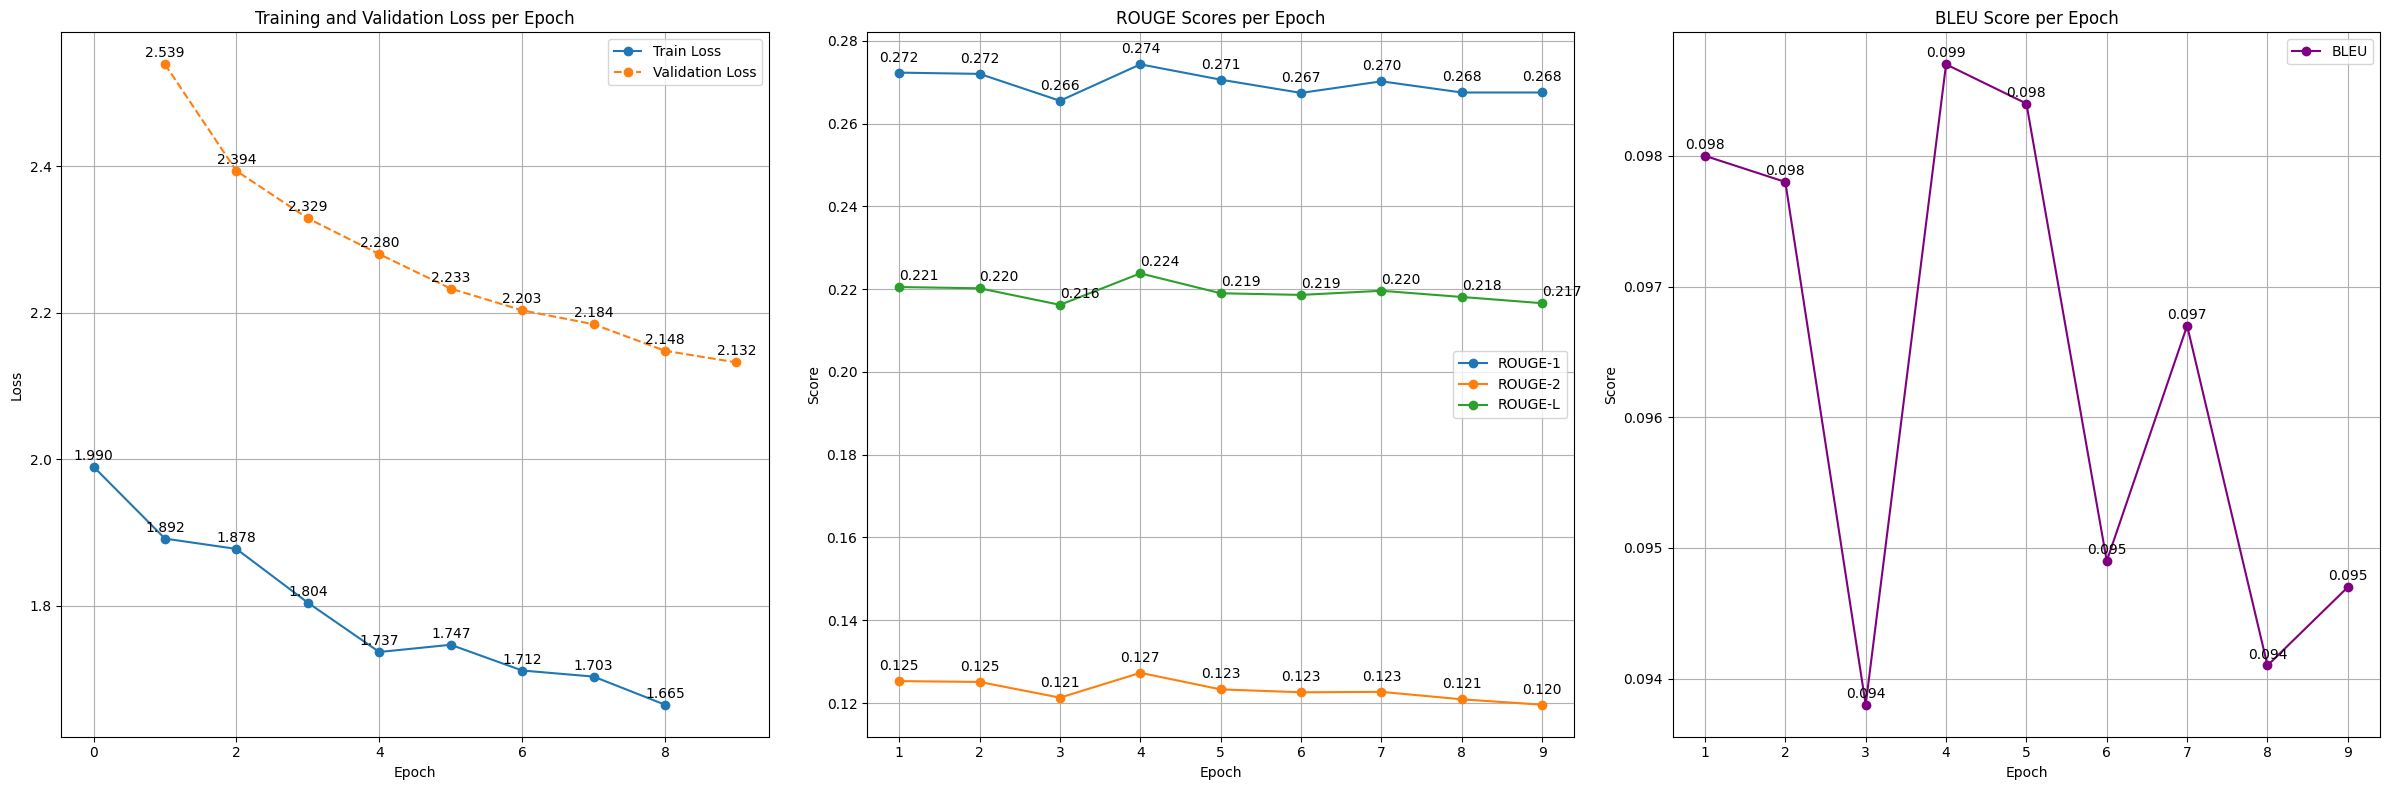

In [ ]:
import matplotlib.pyplot as plt

log_history = trainer_s1.state.log_history

# Dictionaries untuk evaluasi per epoch
train_losses_per_epoch = {}
val_metrics_per_epoch = {}

for entry in log_history:
    epoch_float = entry['epoch']
    epoch_int = int(epoch_float)

    # training loss
    if 'loss' in entry and 'eval_loss' not in entry:
        train_losses_per_epoch[epoch_int] = entry['loss']

    # metrik evaluasi
    if 'eval_loss' in entry:
        val_metrics_per_epoch[epoch_int] = {
            'loss': entry.get('eval_loss'),
            'rouge1': entry.get('eval_rouge1'),
            'rouge2': entry.get('eval_rouge2'),
            'rougeL': entry.get('eval_rougeL'),
            'bleu': entry.get('eval_bleu')
        }

epochs_train_plot = sorted(train_losses_per_epoch.keys())
train_loss_plot = [train_losses_per_epoch[e] for e in epochs_train_plot]

epochs_val_plot = sorted(val_metrics_per_epoch.keys())
val_loss_plot = [val_metrics_per_epoch[e]['loss'] for e in epochs_val_plot]
rouge1_plot = [val_metrics_per_epoch[e]['rouge1'] for e in epochs_val_plot]
rouge2_plot = [val_metrics_per_epoch[e]['rouge2'] for e in epochs_val_plot]
rougeL_plot = [val_metrics_per_epoch[e]['rougeL'] for e in epochs_val_plot]
bleu_plot = [val_metrics_per_epoch[e]['bleu'] for e in epochs_val_plot]

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Training and Validation Loss
axes[0].plot(epochs_train_plot, train_loss_plot, label='Train Loss', marker='o', linestyle='-')
axes[0].plot(epochs_val_plot, val_loss_plot, label='Validation Loss', marker='o', linestyle='--')
axes[0].set_title('Training and Validation Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)
for i, epoch in enumerate(epochs_train_plot):
    axes[0].annotate(f'{train_loss_plot[i]:.3f}', (epoch, train_loss_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)
for i, epoch in enumerate(epochs_val_plot):
    axes[0].annotate(f'{val_loss_plot[i]:.3f}', (epoch, val_loss_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)

# ROUGE scores (ROUGE-1, ROUGE-2, ROUGE-L)
axes[1].plot(epochs_val_plot, rouge1_plot, label='ROUGE-1', marker='o', linestyle='-')
axes[1].plot(epochs_val_plot, rouge2_plot, label='ROUGE-2', marker='o', linestyle='-')
axes[1].plot(epochs_val_plot, rougeL_plot, label='ROUGE-L', marker='o', linestyle='-')
axes[1].set_title('ROUGE Scores per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(True)
for i, epoch in enumerate(epochs_val_plot):
    if rouge1_plot[i] is not None:
        axes[1].annotate(f'{rouge1_plot[i]:.3f}', (epoch, rouge1_plot[i]), textcoords="offset points", xytext=(0,8), ha='center', fontsize=10)
    if rouge2_plot[i] is not None:
        axes[1].annotate(f'{rouge2_plot[i]:.3f}', (epoch, rouge2_plot[i]), textcoords="offset points", xytext=(0,8), ha='center', fontsize=10)
    if rougeL_plot[i] is not None:
        axes[1].annotate(f'{rougeL_plot[i]:.3f}', (epoch, rougeL_plot[i]), textcoords="offset points", xytext=(0,8), ha='left', va='center', fontsize=10)

# BLEU score
axes[2].plot(epochs_val_plot, bleu_plot, label='BLEU', marker='o', linestyle='-', color='purple')
axes[2].set_title('BLEU Score per Epoch')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Score')
axes[2].legend()
axes[2].grid(True)
for i, epoch in enumerate(epochs_val_plot):
    if bleu_plot[i] is not None:
        axes[2].annotate(f'{bleu_plot[i]:.3f}', (epoch, bleu_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('training_curve_step1.png', dpi=150)
plt.show()

## 11. Evaluasi Step 1

In [ ]:
# Evaluasi pada test set
eval_s1 = trainer_s1.evaluate(test_l6_tok)
print('Evaluasi Step 1 (Liputan6 Test Set):')
print(f"  ROUGE-1 : {eval_s1['eval_rouge1']:.4f}")
print(f"  ROUGE-2 : {eval_s1['eval_rouge2']:.4f}")
print(f"  ROUGE-L : {eval_s1['eval_rougeL']:.4f}")
print(f"  BLEU    : {eval_s1['eval_bleu']:.4f}")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
1.664875,2.087504,9,0.294100,0.146200,0.240200,0.111800


Evaluasi Step 1 (Liputan6 Test Set):
  ROUGE-1 : 0.2941
  ROUGE-2 : 0.1462
  ROUGE-L : 0.2402
  BLEU    : 0.1118


In [ ]:
def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = clean_text(text)   # IndoBART: tanpa prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)


model_s1.to(device)

sample_artikel   = val_l6[0][INPUT_COL_L6]
sample_ringkasan = val_l6[0][TARGET_COL_L6]

print('=== Uji Ringkasan Step 1 ===')
print('\n[Artikel] (200 karakter pertama):')
print(liputan6_to_str(sample_artikel)[:200], '...')
print('\n[Ringkasan Referensi]:')
print(liputan6_to_str(sample_ringkasan))
print('\n[Ringkasan Model Step 1]:')
print(generate_summary(sample_artikel, model_s1, tokenizer, device))

=== Uji Ringkasan Step 1 ===

[Artikel] (200 karakter pertama):
Liputan6 . com , Jakarta : Konflik antara eksekutif dan legislatif semakin menganga . Bahkan kenyataan ini juga terjadi di lapisan bawah ( masyarakat ) . Padahal , semua perselisihan itu dapat dihinda ...

[Ringkasan Referensi]:
Gus Dur mengakui ada ketidakharmonisan antara eksekutif dan legislatif . Permintaan DPR mendesaknya mundur , sangat tak efektif . Perselisihan di lapisan bawah sebenarnya dapat dihindari .

[Ringkasan Model Step 1]:
kenyataan ini juga terjadi di lapisan bawah ( masyarakat ) . padahal , semua perselisihan itu dapat dihindari , asalkan elite politik mau menyelesaikan masalah bangsa secara damai dan konstitusional .


## 12. Simpan Model Step 1

In [ ]:
import shutil

# Simpan LoRA adapter Step 1
model_s1.save_pretrained(STEP1_OUTPUT_DIR)
tokenizer.save_pretrained(STEP1_OUTPUT_DIR)
print(f'LoRA adapter Step 1 tersimpan di: {STEP1_OUTPUT_DIR}')

# Merge dan simpan model penuh Step 1
merged_s1 = model_s1.merge_and_unload()
merged_s1.save_pretrained(STEP1_MERGED_DIR)
tokenizer.save_pretrained(STEP1_MERGED_DIR)
print(f'Merged model Step 1 tersimpan di: {STEP1_MERGED_DIR}')

# Simpan ke Google Drive
for folder in [STEP1_OUTPUT_DIR, STEP1_MERGED_DIR]:
    dest = f'/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/{folder}'
    if os.path.exists(dest):
        shutil.rmtree(dest)
    shutil.copytree(folder, dest)
    print(f'Tersimpan di Google Drive: MyDrive/{folder}')

/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:452: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


LoRA adapter Step 1 tersimpan di: ./indobart-lora-step1-liputan6


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model Step 1 tersimpan di: ./indobart-merged-step1-liputan6
Tersimpan di Google Drive: MyDrive/./indobart-lora-step1-liputan6
Tersimpan di Google Drive: MyDrive/./indobart-merged-step1-liputan6


---
# STEP 2 — Fine-Tuning dengan Dataset BPS DKI Jakarta

## 13. Load & Persiapan Dataset BPS DKI

In [ ]:
import gdown
import pandas as pd

url_rawdata = "https://docs.google.com/spreadsheets/d/17D0qGiVQ6837FH3Hck5PsVwfX0-UuGi5/export?format=xlsx"
gdown.download(url_rawdata, "raw_data.xlsx", quiet=False, fuzzy=True)

df_bps = pd.read_excel('raw_data.xlsx')
print('Shape:', df_bps.shape)
print('Kolom:', df_bps.columns.tolist())
print('\nNull values:')
print(df_bps.isnull().sum())
print('\nContoh data:')
df_bps.head(3)

Downloading...
From: https://docs.google.com/spreadsheets/d/17D0qGiVQ6837FH3Hck5PsVwfX0-UuGi5/export?format=xlsx
To: /content/raw_data.xlsx
2.56MB [00:00, 14.3MB/s]


Shape: (2316, 6)
Kolom: ['Nomor', 'Judul', 'Link', 'Ringkasan', 'Full_Content', 'Indikator']

Null values:
Nomor           0
Judul           0
Link            0
Ringkasan       0
Full_Content    0
Indikator       0
dtype: int64

Contoh data:


,Nomor,Judul,Link,Ringkasan,Full_Content,Indikator
0,1,BPS: Kemiskinan Bisa Ditekan dengan Fokus di Jawa,https://www.republika.co.id/berita/qwj4qa328/b...,BPS melaporkan angka kemiskinan di Indonesia h...,"REPUBLIKA.CO.ID, JAKARTA -- Kepala Badan Pusat...",Lainnya
1,2,Mendes PDTT Minta Ruang Isolasi Desa Diaktifkan,https://microsite.suara.com/kemendesa/read/202...,"Menteri Desa, Pembangunan Daerah Tertinggal, d...",Mendes PDTT Minta Ruang Isolasi Desa Diaktifka...,Lainnya
2,3,"Tambah 1.610 Pasien, Positif Covid-19 di Jakar...",https://jakarta.suara.com/read/2021/08/03/2229...,Jumlah kasus pasien positif terjangkit Covid-1...,SuaraJakarta.id - Jumlah kasus pasien positif ...,Lainnya


In [ ]:
INPUT_COL_BPS  = 'Full_Content'
TARGET_COL_BPS = 'Ringkasan'

df_bps = df_bps[[INPUT_COL_BPS, TARGET_COL_BPS]].dropna().reset_index(drop=True)
print(f'Total data BPS DKI: {len(df_bps)}')

df_bps['panjang_artikel']   = df_bps[INPUT_COL_BPS].str.split().str.len()
df_bps['panjang_ringkasan'] = df_bps[TARGET_COL_BPS].str.split().str.len()
print(f'\nRata-rata panjang artikel   : {df_bps["panjang_artikel"].mean():.0f} kata')
print(f'Rata-rata panjang ringkasan : {df_bps["panjang_ringkasan"].mean():.0f} kata')

Total data BPS DKI: 2316

Rata-rata panjang artikel   : 328 kata
Rata-rata panjang ringkasan : 69 kata


In [ ]:
from sklearn.model_selection import train_test_split

df_train_bps, df_temp_bps = train_test_split(df_bps, test_size=0.2, random_state=42)
df_val_bps, df_test_bps   = train_test_split(df_temp_bps, test_size=0.5, random_state=42)

print(f'Train BPS : {len(df_train_bps)}')
print(f'Val BPS   : {len(df_val_bps)}')
print(f'Test BPS  : {len(df_test_bps)}')

Train BPS : 1852
Val BPS   : 232
Test BPS  : 232


In [ ]:
def tokenize_bps(examples):
    return tokenize_fn(examples, INPUT_COL_BPS, TARGET_COL_BPS)

train_bps_ds = Dataset.from_pandas(df_train_bps.reset_index(drop=True))
val_bps_ds   = Dataset.from_pandas(df_val_bps.reset_index(drop=True))
test_bps_ds  = Dataset.from_pandas(df_test_bps.reset_index(drop=True))

cols_bps      = train_bps_ds.column_names
train_bps_tok = train_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)
val_bps_tok   = val_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)
test_bps_tok  = test_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)

print('Tokenisasi BPS DKI selesai.')

Map:   0%|          | 0/1852 [00:00<?, ? examples/s]

Map:   0%|          | 0/232 [00:00<?, ? examples/s]

Map:   0%|          | 0/232 [00:00<?, ? examples/s]

Tokenisasi BPS DKI selesai.


## 14. Load Model Step 1 & Terapkan LoRA Baru (Step 2)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# load merged model Step 1 sebagai base untuk Step 2
print('Memuat merged model Step 1 sebagai base Step 2...')
base_model_s2 = AutoModelForSeq2SeqLM.from_pretrained(f'/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/{STEP1_MERGED_DIR}')

base_model_s2.resize_token_embeddings(len(tokenizer))
base_model_s2.config.decoder_start_token_id = tokenizer.eos_token_id

base_model_s2.config.use_cache = False

# terapkan LoRA baru untuk Step 2
model_s2 = get_peft_model(base_model_s2, lora_config)
model_s2.enable_input_require_grads()
model_s2.print_trainable_parameters()

Mounted at /content/drive
Memuat merged model Step 1 sebagai base Step 2...


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

trainable params: 884,736 || all params: 132,444,672 || trainable%: 0.6680


## 15. Training Step 2 — BPS DKI

In [ ]:
data_collator_s2 = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model_s2,
    padding=True,
    pad_to_multiple_of=8,
    label_pad_token_id=-100,
)

training_args_s2 = Seq2SeqTrainingArguments(
    output_dir="/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART",

    save_strategy="epoch",
    save_steps=1,
    save_total_limit=3,
    logging_strategy="epoch",
    logging_steps=1,
    eval_strategy='epoch',
    eval_steps=1,

    num_train_epochs=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=1e-5,

    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,     # generasi
    generation_max_length=256,
    generation_num_beams=4,

    fp16=False,
    seed=42,
    report_to='none',
)

trainer_s2 = Seq2SeqTrainer(
    model=model_s2,
    args=training_args_s2,
    train_dataset=train_bps_tok,
    eval_dataset=val_bps_tok,
    processing_class=tokenizer,
    data_collator=data_collator_s2,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)], # in 3 epoch
)

print('Trainer Step 2 siap. Memulai training...')


Trainer Step 2 siap. Memulai training...


In [ ]:
result_s2 = trainer_s2.train()
print('\nHasil Training Step 2:')
print(result_s2.metrics)

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
1,4.939123,1.117970,0.382200,0.296900,0.337700,0.222700
2,5.175797,1.114161,0.381800,0.295000,0.333200,0.243800
3,4.900309,1.102091,0.390400,0.300900,0.338200,0.253300
4,4.954734,1.091872,0.378500,0.289900,0.324400,0.243800
5,4.978169,1.086416,0.382700,0.293700,0.331600,0.244900
6,4.985902,1.083200,0.380300,0.289700,0.328900,0.240600



Hasil Training Step 2:
{'train_runtime': 1175.0198, 'train_samples_per_second': 15.761, 'train_steps_per_second': 0.494, 'total_flos': 3418002032689152.0, 'train_loss': 4.968723373851557, 'epoch': 6.0}


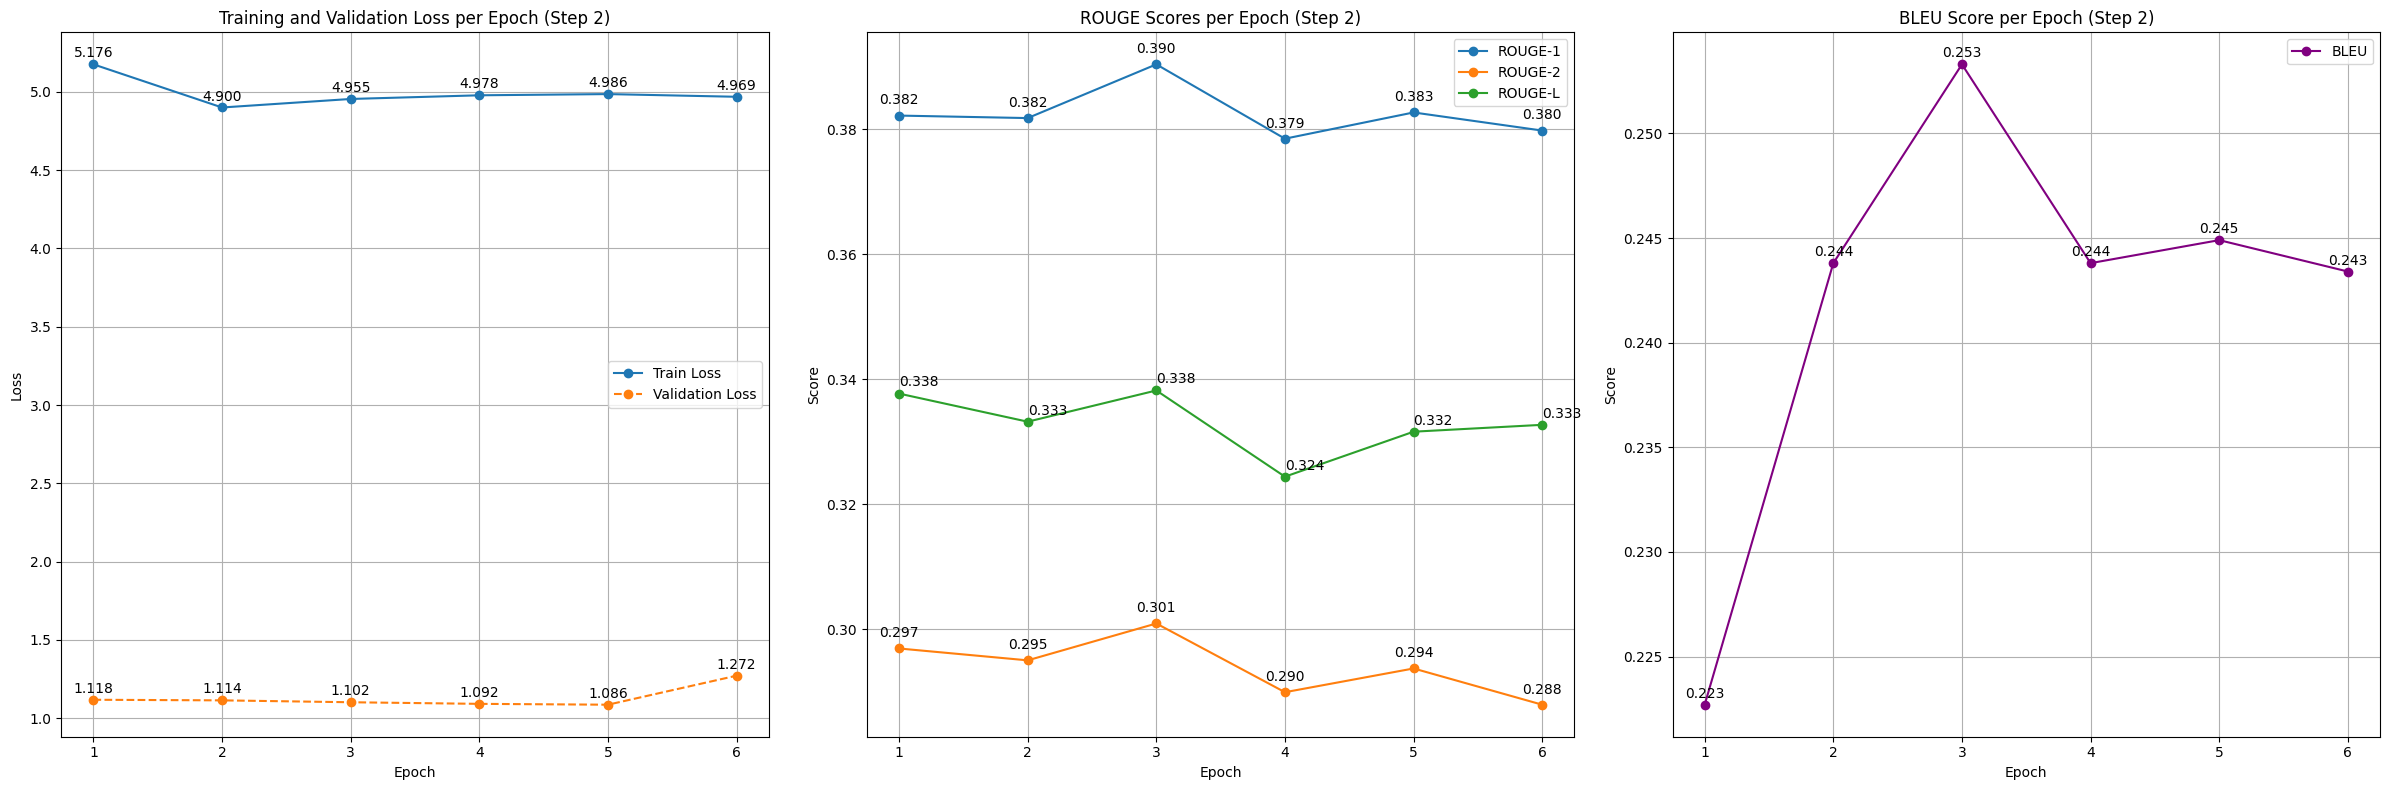

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

log_history = trainer_s2.state.log_history

epoch_metrics = {}

for entry in log_history:
    epoch_float = entry['epoch']
    epoch_int = int(epoch_float)

    # Inisialisasi
    if epoch_int not in epoch_metrics:
        epoch_metrics[epoch_int] = {
            'train_loss': None,
            'val_loss': None,
            'rouge1': None,
            'rouge2': None,
            'rougeL': None,
            'bleu': None
        }

    # training loss
    if 'loss' in entry:
        epoch_metrics[epoch_int]['train_loss'] = entry['loss']
    elif 'train_loss' in entry and 'eval_loss' not in entry:
        epoch_metrics[epoch_int]['train_loss'] = entry['train_loss']

    # metrik evaluasi
    if 'eval_loss' in entry:
        epoch_metrics[epoch_int]['val_loss'] = entry.get('eval_loss')
        epoch_metrics[epoch_int]['rouge1'] = entry.get('eval_rouge1')
        epoch_metrics[epoch_int]['rouge2'] = entry.get('eval_rouge2')
        epoch_metrics[epoch_int]['rougeL'] = entry.get('eval_rougeL')
        epoch_metrics[epoch_int]['bleu'] = entry.get('eval_bleu')

epochs_to_plot = sorted([e for e, metrics in epoch_metrics.items() if metrics['val_loss'] is not None])

train_loss_plot = []
val_loss_plot = []
rouge1_plot = []
rouge2_plot = []
rougeL_plot = []
bleu_plot = []

for epoch in epochs_to_plot:
    metrics = epoch_metrics[epoch]
    train_loss_plot.append(metrics['train_loss'] if metrics['train_loss'] is not None else np.nan)
    val_loss_plot.append(metrics['val_loss'])
    rouge1_plot.append(metrics['rouge1'])
    rouge2_plot.append(metrics['rouge2'])
    rougeL_plot.append(metrics['rougeL'])
    bleu_plot.append(metrics['bleu'])

# konversi ke list
epochs_plot_list = list(epochs_to_plot)

fig, axes = plt.subplots(1, 3, figsize=(24, 8)) # Increased figure size

# Plot Loss
axes[0].plot(epochs_plot_list, train_loss_plot, label='Train Loss', marker='o', linestyle='-')
axes[0].plot(epochs_plot_list, val_loss_plot, label='Validation Loss', marker='o', linestyle='--')
axes[0].set_title('Training and Validation Loss per Epoch (Step 2)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)
for i, epoch in enumerate(epochs_plot_list):
    if not np.isnan(train_loss_plot[i]):
        axes[0].annotate(f'{train_loss_plot[i]:.3f}', (epoch, train_loss_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)
    if not np.isnan(val_loss_plot[i]):
        axes[0].annotate(f'{val_loss_plot[i]:.3f}', (epoch, val_loss_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)

# Plot ROUGE
axes[1].plot(epochs_plot_list, rouge1_plot, label='ROUGE-1', marker='o', linestyle='-')
axes[1].plot(epochs_plot_list, rouge2_plot, label='ROUGE-2', marker='o', linestyle='-')
axes[1].plot(epochs_plot_list, rougeL_plot, label='ROUGE-L', marker='o', linestyle='-')
axes[1].set_title('ROUGE Scores per Epoch (Step 2)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(True)
for i, epoch in enumerate(epochs_plot_list):
    if rouge1_plot[i] is not None:
        axes[1].annotate(f'{rouge1_plot[i]:.3f}', (epoch, rouge1_plot[i]), textcoords="offset points", xytext=(0,8), ha='center', fontsize=10)
    if rouge2_plot[i] is not None:
        axes[1].annotate(f'{rouge2_plot[i]:.3f}', (epoch, rouge2_plot[i]), textcoords="offset points", xytext=(0,8), ha='center', fontsize=10)
    if rougeL_plot[i] is not None:
        axes[1].annotate(f'{rougeL_plot[i]:.3f}', (epoch, rougeL_plot[i]), textcoords="offset points", xytext=(0,8), ha='left', va='center', fontsize=10)

# Plot BLEU
axes[2].plot(epochs_plot_list, bleu_plot, label='BLEU', marker='o', linestyle='-', color='purple')
axes[2].set_title('BLEU Score per Epoch (Step 2)')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Score')
axes[2].legend()
axes[2].grid(True)
for i, epoch in enumerate(epochs_plot_list):
    if bleu_plot[i] is not None:
        axes[2].annotate(f'{bleu_plot[i]:.3f}', (epoch, bleu_plot[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('training_curve_step2.png', dpi=150)
plt.show()

## 16. Evaluasi Step 2 pada Test Set BPS DKI

In [ ]:
# Evaluasi pada test set BPS DKI
eval_s2 = trainer_s2.evaluate(test_bps_tok)
print('Evaluasi Step 2 (BPS DKI Test Set):')
print(f"  ROUGE-1 : {eval_s2['eval_rouge1']:.4f}")
print(f"  ROUGE-2 : {eval_s2['eval_rouge2']:.4f}")
print(f"  ROUGE-L : {eval_s2['eval_rougeL']:.4f}")
print(f"  BLEU    : {eval_s2['eval_bleu']:.4f}")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
4.985902,1.271759,6,0.379800,0.287900,0.332700,0.243400


Evaluasi Step 2 (BPS DKI Test Set):
  ROUGE-1 : 0.3798
  ROUGE-2 : 0.2879
  ROUGE-L : 0.3327
  BLEU    : 0.2434


In [ ]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

# Load model_s1 dari Drive
STEP1_MERGED_DIR_DRIVE = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/indobart-merged-step1-liputan6'

print('Memuat model Step 1 dari Drive...')
model_s1 = AutoModelForSeq2SeqLM.from_pretrained(STEP1_MERGED_DIR_DRIVE, local_files_only=True)
model_s1.config.decoder_start_token_id = tokenizer.eos_token_id
model_s1.eval()
print('✓ Model Step 1 berhasil dimuat.')

print('Memuat model Step 2 dari Drive...')
model_s2 = AutoModelForSeq2SeqLM.from_pretrained(STEP2_MERGED_DIR_DRIVE, local_files_only=True)
model_s2.config.decoder_start_token_id = tokenizer.eos_token_id
model_s2.eval()
print('✓ Model Step 2 berhasil dimuat.')

# Perbandingan ROUGE Step 1 vs Step 2 pada BPS DKI test set
model_s1.to(device)
eval_s1_on_bps = trainer_s1.predict(test_bps_tok)

preds_s1  = eval_s1_on_bps.predictions
preds_s1 = np.clip(preds_s1, 0, tokenizer.vocab_size - 1)
preds_s1  = np.where(preds_s1 != -100, preds_s1, tokenizer.pad_token_id)
decoded_s1 = tokenizer.batch_decode(preds_s1, skip_special_tokens=True)

labels_raw = eval_s1_on_bps.label_ids
labels_raw = np.where(labels_raw != -100, labels_raw, tokenizer.pad_token_id)
decoded_ref = tokenizer.batch_decode(labels_raw, skip_special_tokens=True)

rouge_s1_bps = rouge.compute(predictions=decoded_s1, references=decoded_ref)
bleu_s1_bps  = bleu.compute(predictions=decoded_s1, references=[[r] for r in decoded_ref])

print('\n=== Perbandingan ROUGE pada BPS DKI Test Set ===')
print(f"{'Metrik':<12} {'Step 1 (Liputan6)':>20} {'Step 2 (BPS DKI)':>18}")
print('-' * 52)
print(f"{'ROUGE-1':<12} {rouge_s1_bps['rouge1']:>20.4f} {eval_s2['eval_rouge1']:>18.4f}")
print(f"{'ROUGE-2':<12} {rouge_s1_bps['rouge2']:>20.4f} {eval_s2['eval_rouge2']:>18.4f}")
print(f"{'ROUGE-L':<12} {rouge_s1_bps['rougeL']:>20.4f} {eval_s2['eval_rougeL']:>18.4f}")
print(f"{'BLEU':<12} {bleu_s1_bps['bleu']:>20.4f} {eval_s2['eval_bleu']:>18.4f}")

Memuat model Step 1 dari Drive...


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

✓ Model Step 1 berhasil dimuat.



=== Perbandingan ROUGE pada BPS DKI Test Set ===
Metrik          Step 1 (Liputan6)   Step 2 (BPS DKI)
----------------------------------------------------
ROUGE-1                    0.4589             0.3798
ROUGE-2                    0.3658             0.2879
ROUGE-L                    0.4189             0.3327
BLEU                       0.3540             0.2434


In [ ]:
def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = clean_text(text)   # IndoBART: tanpa prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

model_s2.to(device)

sample_bps_artikel   = df_test_bps.iloc[0][INPUT_COL_BPS]
sample_bps_ringkasan = df_test_bps.iloc[0][TARGET_COL_BPS]

print('=== Uji Ringkasan Step 2 (Domain BPS DKI) ===')
print('\n[Artikel] (200 karakter pertama):')
print(sample_bps_artikel[:200], '...')
print('\n[Ringkasan Referensi BPS]:')
print(sample_bps_ringkasan)
print('\n[Ringkasan Model Step 1 pada artikel BPS]:')
print(generate_summary(sample_bps_artikel, model_s1, tokenizer, device))
print('\n[Ringkasan Model Step 2 (final)]:')
print(generate_summary(sample_bps_artikel, model_s2, tokenizer, device))

[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== Uji Ringkasan Step 2 (Domain BPS DKI) ===

[Artikel] (200 karakter pertama):
ILUSTRASI. Pekerja mengerjakan pembuatan mie di Pabrik Mie Samino Ciledug Tangerang, Senin (21/6). Realisasi KUR capai 83%, KemenKopUKM optimalkan pendampingan program ini.

Reporter: Ratih Waseso | E ...

[Ringkasan Referensi BPS]:
ealisasi penyaluran Kredit Usaha Rakyat (KUR) tahun 2021 sampai dengan 3 November 2021 berdasarkan data Sistem Informasi Kredit Program (SIKP) sebesar Rp 237,08 triliun atau sebesar 83,19% kepada 6,28 juta debitur.KUR Super Mikro sebesar Rp 9,02 triliun kepada 1,02 juta debitur, KUR Mikro Rp 147,82 triliun kepada  4,8 juta debitur, KUR Kecil Rp 80,22 triliun kepada 413.886 debitur dan KUR Penempatan TKI Rp 17,29 miliar kepada 1.123 debitur.

[Ringkasan Model Step 1 pada artikel BPS]:


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


sebesar rp 237,08 triliun kepada 6,28 juta debitur. deputi bidang usaha mikro kementerian koperasi dan ukm eddy satriya memaparkan, rincian realisasi penyaluran tersebut .

[Ringkasan Model Step 2 (final)]:
pelaku koperasi dan umkm agar mereka dapat mengakses dan menaikkan skala usahanya. eddy mengatakan sampai dilakukan sosialisasi pendampingan bagi program kur sehingga sudah saatnya untuk dioptimalkan. selain itu, keluhan soal agunan masih dilaporkan, namun kendala tersebut


## 17. Simpan Model Final (Step 2)

In [ ]:
import shutil

# Simpan LoRA adapter Step 2
model_s2.save_pretrained(STEP2_OUTPUT_DIR)
tokenizer.save_pretrained(STEP2_OUTPUT_DIR)
print(f'LoRA adapter Step 2 tersimpan di: {STEP2_OUTPUT_DIR}')

# Merge dan simpan model penuh Step 2 (model FINAL)
merged_s2 = model_s2.merge_and_unload()
merged_s2.save_pretrained(STEP2_MERGED_DIR)
tokenizer.save_pretrained(STEP2_MERGED_DIR)
print(f'Merged model Step 2 tersimpan di: {STEP2_MERGED_DIR}')

# Simpan ke Google Drive
for folder in [STEP2_OUTPUT_DIR, STEP2_MERGED_DIR]:
    dest = f'/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/{folder}'
    if os.path.exists(dest):
        shutil.rmtree(dest)
    shutil.copytree(folder, dest)
    print(f'Tersimpan di Google Drive: MyDrive/{folder}')

/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:452: UserWarning: Setting `save_embedding_layers` to `True` as the embedding layer has been resized during finetuning.
  warnings.warn(


LoRA adapter Step 2 tersimpan di: ./indobart-lora-step2-bps


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model Step 2 tersimpan di: ./indobart-merged-step2-bps
Tersimpan di Google Drive: MyDrive/./indobart-lora-step2-bps
Tersimpan di Google Drive: MyDrive/./indobart-merged-step2-bps


## 18. Load Model Final untuk Inference

In [ ]:
# Load merged model final
# from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./indobart-merged-step2-bps')
# model_loaded = AutoModelForSeq2SeqLM.from_pretrained('./indobart-merged-step2-bps')
# model_loaded.eval()

from google.colab import drive
drive.mount('/content/drive')
STEP1_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/indobart-merged-step1-liputan6'
STEP2_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/indobart-merged-step2-bps'

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
tokenizer_step1_loaded = AutoTokenizer.from_pretrained(STEP1_DIR, local_files_only=True)
model_step1_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP1_DIR, local_files_only=True
)
model_step1_loaded.to(device)
model_step1_loaded.eval()
print(f'Model step 1 berhasil dimuat dan dipindah ke: {device}')

tokenizer_step2_loaded = AutoTokenizer.from_pretrained(STEP2_DIR, local_files_only=True)
model_step2_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP2_DIR, local_files_only=True
)
model_step2_loaded.to(device)
model_step2_loaded.eval()
print(f'Model step 2 berhasil dimuat dan dipindah ke: {device}')

# Load LoRA Adapter
# from peft import PeftModel
# from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./indobart-lora-step2-bps')
# base = AutoModelForSeq2SeqLM.from_pretrained('./indobart-merged-step1-liputan6')
# model_loaded = PeftModel.from_pretrained(base, './indobart-lora-step2-bps')
# model_loaded.eval()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Model step 1 berhasil dimuat dan dipindah ke: cuda


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Model step 2 berhasil dimuat dan dipindah ke: cuda


In [ ]:
berita = """Gubernur DKI Jakarta, Pramono Anung, menyatakan bahwa partisipasi masyarakat dalam Pendataan Lapangan Sensus Ekonomi 2026 (SE2026) yang dilakukan Badan Pusat Statistik (BPS) penting untuk menghasilkan data ekonomi Jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Gubernur sendiri menerima menerima petugas BPS DKI Jakarta yang melakukan pendataan Sensus Ekonomi 2026, baru-baru ini.
"Petugas BPS yang datang hari ini secara langsung menanyakan sesuai dengan tugas dalam melakukan sensus. Saya menjawab secara apa adanya, sesuai kondisi sebenarnya," kata Pramono.
Ia kemudian mendorong masyarakat yang belum terdata maupun yang masih ragu memberikan informasi agar terbuka kepada petugas BPS. Menurutnya, data yang akurat membantu pemerintah memahami kondisi perekonomian Jakarta secara lebih utuh.
"Saya mengimbau kepada masyarakat di Jakarta untuk membantu BPS dalam melakukan tugas mereka, yaitu sensus ekonomi. Saya mengimbau seluruh masyarakat Jakarta untuk memberikan data apa adanya. Jangan tertutup," ujarnya.
Pramono menegaskan, informasi yang diberikan dalam Sensus Ekonomi 2026 bersifat rahasia. Pendataan dipastikan tidak berkaitan dengan perpajakan ataupun kepentingan lain di luar kebutuhan statistik.
"Ini betul-betul adalah sensus ekonomi untuk mengetahui potret kondisi dan keadaan di Jakarta. Masyarakat diminta memberikan jawaban apa adanya, sesuai dengan kondisi yang sebenarnya, karena data ini akan menjadi referensi dalam mengambil keputusan," tutur Pramono.
Sebagai salah satu pusat kegiatan ekonomi terbesar di Indonesia, keberagaman kegiatan usaha yang tumbuh di Jakarta, mulai dari usaha rumahan, UMKM, hingga perusahaan berskala besar dan internasional, perlu tercatat agar gambaran perekonomian Jakarta tidak hanya mencerminkan kegiatan usaha yang terlihat secara kasatmata.
Selama pendataan, petugas BPS mendatangi berbagai lokasi usaha, seperti mal, kawasan bisnis, pasar, pertokoan, pusat perbelanjaan, rumah, dan apartemen untuk bertemu langsung dengan pelaku usaha dan masyarakat.
Sementara, sebagian responden mengikuti pendataan melalui pengisian kuesioner secara mandiri.
Sensus Ekonomi ini bukan hanya menghitung jumlah usaha. Data yang dikumpulkan mencakup jenis kegiatan usaha, produk dan jasa yang dihasilkan, skala usaha, tenaga kerja, pemanfaatan teknologi, serta berbagai karakteristik lainnya.
Data itu diharapkan memberikan gambaran yang lebih lengkap mengenai perkembangan ekonomi Jakarta, termasuk usaha yang selama ini belum tercatat dalam data administrasi pemerintah.
Untuk diketahui, hasil SE2026 akan menjadi salah satu rujukan Pemerintah Provinsi (Pemprov) DKI Jakarta dalam menyusun program, kebijakan, regulasi, dan intervensi yang lebih tepat sasaran berdasarkan kondisi ekonomi terkini.
"Data yang benar akan membantu pemerintah mengambil keputusan yang benar. Karena itu saya mengajak masyarakat untuk ikut menyukseskan sensus ekonomi," ujar Gubernur.
Dalam kesempatan yang sama, ia juga meminta Dinas Pendidikan DKI Jakarta melakukan pengecekan ulang terhadap mahasiswa penerima Kartu Jakarta Mahasiswa Unggul (KJMU) yang terdampak perubahan data desil.
Langkah ini bertujuan memastikan mahasiswa yang sebelumnya menerima KJMU tidak kehilangan akses pendidikan akibat perubahan data yang masih perlu diverifikasi.
Sementara itu, Sekretaris Utama BPS RI, Zulkipli, mengatakan pelaksanaan pendataan Sensus Ekonomi 2026 di Jakarta berjalan lancar.
Berdasarkan pre-list yang tersedia, BPS telah melakukan pendataan sebesar 111 persen. Hingga kini, masih terdapat sejumlah unit usaha yang belum ditemukan atau dokumennya masih dalam proses penelusuran.
"Waktu kita masih ada sampai dengan 15 September. Kami akan mendatangi kembali perusahaan-perusahaan itu serta menemukan kembali yang tadinya belum ditemukan dalam pre-list kami," kata Zulikpli.
Zulkipli juga mengajak masyarakat dan pelaku usaha yang belum terdata untuk menghubungi Kantor BPS. Pendataan masih akan berlangsung hingga pertengahan September 2026.
"Untuk masyarakat di DKI Jakarta dapat membantu BPS dalam pelaksanaan Sensus Ekonomi 2026. Bagi yang belum terdata, nanti kita bisa lakukan pendataan atau bisa menghubungi kantor BPS. Waktu kita masih ada hingga pertengahan September 2026," pungkas Zulkipli.
https://www.cnnindonesia.com/nasional/20260901114547-25-1398660/gubernur-dki-ikuti-sensus-ekonomi-dorong-warga-terbuka-pada-petugas"""


import time
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = clean_text(text)   # IndoBART: tanpa prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

def timed_summary(text, model, tokenizer, device):
    """Menghitung runtime inferensi (dalam detik) untuk meringkas satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    summary = generate_summary(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return summary, duration_s

print('\n=== Uji Ringkasan dan Waktu Inferensi ===')

# Inference for Model Step 1
print('\n--- Model Step 1 (Fine-tuned on Liputan6) ---')
summary_s1, duration_s1 = timed_summary(berita, model_step1_loaded, tokenizer_step1_loaded, device)
print(f'[Ringkasan Model Step 1]:\n{summary_s1}')
print(f'Waktu Eksekusi : {duration_s1:.3f} s')

# Inference for Model Step 2
print('\n--- Model Step 2 (Fine-tuned on BPS DKI) ---')
summary_s2, duration_s2 = timed_summary(berita, model_step2_loaded, tokenizer_step2_loaded, device)
print(f'[Ringkasan Model Step 2]:\n{summary_s2}')
print(f'Waktu Eksekusi : {duration_s2:.3f} s')

[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== Uji Ringkasan dan Waktu Inferensi ===

--- Model Step 1 (Fine-tuned on Liputan6) ---


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[Ringkasan Model Step 1]:
pendataan lapangan sensus ekonomi 2026 (se2026) yang dilakukan badan pusat statistik (bps) penting untuk menghasilkan data ekonomi jakarta yang akurat, sebagai dasar pemerintah dalam .
Waktu Eksekusi : 0.861 s

--- Model Step 2 (Fine-tuned on BPS DKI) ---
[Ringkasan Model Step 2]:
pendataan lapangan sensus ekonomi 2026 (se2026) yang dilakukan badan pusat statistik (bps) penting untuk menghasilkan data ekonomi jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan. gubernur sendiri menerima
Waktu Eksekusi : 0.954 s


In [ ]:
# Inferensi data Human Evaluation
from google.colab import drive
drive.mount('/content/drive')
STEP1_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/indobart-merged-step1-liputan6'
STEP2_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/indobart-merged-step2-bps'

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
tokenizer_step1_loaded = AutoTokenizer.from_pretrained(STEP1_DIR, local_files_only=True)
model_step1_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP1_DIR, local_files_only=True
)
model_step1_loaded.to(device)
model_step1_loaded.eval()
print(f'Model step 1 berhasil dimuat dan dipindah ke: {device}')

tokenizer_step2_loaded = AutoTokenizer.from_pretrained(STEP2_DIR, local_files_only=True)
model_step2_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP2_DIR, local_files_only=True
)
model_step2_loaded.to(device)
model_step2_loaded.eval()
print(f'Model step 2 berhasil dimuat dan dipindah ke: {device}')

import gdown
import pandas as pd

url_rawdata = "https://docs.google.com/spreadsheets/d/1pstC3_51qAytcffcvl-lfGnHr_RbOPK3/export?format=xlsx"
gdown.download(url_rawdata, "humaneval_data.xlsx", quiet=False, fuzzy=True)

df_he = pd.read_excel('humaneval_data.xlsx')
print('Shape:', df_he.shape)
print('Kolom:', df_he.columns.tolist())
print('\nNull values:')
print(df_he.isnull().sum())
print('\nContoh data:')
df_he.head(3)

import time
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = clean_text(text)   # IndoBART: tanpa prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

def timed_summary(text, model, tokenizer, device):
    """Menghitung runtime inferensi (dalam detik) untuk meringkas satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    summary = generate_summary(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return summary, duration_s

import numpy as np
TEXT_COLUMN = 'Full_Content'

texts_he = df_he[TEXT_COLUMN].tolist()

# Warm-up
for text in texts_he:
    _ = timed_summary(text, model_step1_loaded, tokenizer_step1_loaded, device)
    _ = timed_summary(text, model_step2_loaded, tokenizer_step2_loaded, device)

durasi_step1_s   = []
ringkasan_step1  = []
durasi_step2_s   = []
ringkasan_step2  = []

for i, text in enumerate(texts_he):
    summary, duration = timed_summary(text, model_step1_loaded, tokenizer_step1_loaded, device)
    durasi_step1_s.append(duration)
    ringkasan_step1.append(summary)
    print(f"[{i+1}/{len(texts_he)}] {duration:.2f} s  -> {summary[:60]}...")

for i, text in enumerate(texts_he):
    summary, duration = timed_summary(text, model_step2_loaded, tokenizer_step2_loaded, device)
    durasi_step2_s.append(duration)
    ringkasan_step2.append(summary)
    print(f"[{i+1}/{len(texts_he)}] {duration:.2f} s  -> {summary[:60]}...")

durasi_step1_s = np.array(durasi_step2_s)

print(f"\n=== Runtime Inferensi IndoBART Step 1 ({len(texts_he)} berita, {device}) ===")
print(f"Rata-rata : {durasi_step1_s.mean():.2f} s")
print(f"Std. dev  : {durasi_step1_s.std():.2f} s")
print(f"Median    : {np.median(durasi_step1_s):.2f} s")
print(f"Min / Max : {durasi_step1_s.min():.2f} s / {durasi_step1_s.max():.2f} s")
print(f"Total     : {durasi_step1_s.sum():.2f} s")

# Simpan hasil generate + waktu ke kolom baru
df_he['Ringkasan_IndoBART_Step1']  = ringkasan_step1
df_he['Runtime_IndoBART_Step1_s']  = durasi_step1_s

durasi_step2_s = np.array(durasi_step2_s)

print(f"\n=== Runtime Inferensi IndoBART Step 2 ({len(texts_he)} berita, {device}) ===")
print(f"Rata-rata : {durasi_step2_s.mean():.2f} s")
print(f"Std. dev  : {durasi_step2_s.std():.2f} s")
print(f"Median    : {np.median(durasi_step2_s):.2f} s")
print(f"Min / Max : {durasi_step2_s.min():.2f} s / {durasi_step2_s.max():.2f} s")
print(f"Total     : {durasi_step2_s.sum():.2f} s")

# Simpan hasil generate + waktu ke kolom baru
df_he['Ringkasan_IndoBART_Step2']  = ringkasan_step2
df_he['Runtime_IndoBART_Step2_s']  = durasi_step2_s

output_path = 'humaneval_hasil_indobart.xlsx'
df_he.to_excel(output_path, index=False)

# Salin juga ke Google Drive
# import shutil
# drive_dest = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBART/humaneval_hasil_indobart.xlsx'
# shutil.copy(output_path, drive_dest)
# print(f"Disalin ke Drive: {drive_dest}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Model step 1 berhasil dimuat dan dipindah ke: cuda


Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Model step 2 berhasil dimuat dan dipindah ke: cuda


...

[27/30] 1.20 s  -> para seniman di ibu kota jakarta. banyak pameran serta pertu...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[28/30] 1.00 s  -> pemutusan hubungan kerja (phk) di jakarta. diketahui, berdas...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[29/30] 0.89 s  -> pemerintah, dari lembaga negara yang tidak selalu berjalan p...
[30/30] 0.78 s  -> sedang melakukan uji coba program makan bergizi gratis. penj...

=== Runtime Inferensi IndoBART Step 1 (30 berita, cuda) ===
Rata-rata : 0.96 s
Std. dev  : 0.15 s
Median    : 0.93 s
Min / Max : 0.77 s / 1.29 s
Total     : 28.91 s

=== Runtime Inferensi IndoBART Step 2 (30 berita, cuda) ===
Rata-rata : 0.96 s
Std. dev  : 0.15 s
Median    : 0.93 s
Min / Max : 0.77 s / 1.29 s
Total     : 28.91 s


In [ ]:
# Inferensi MDS
import numpy as np
import time

num_articles = len(df_he)
if num_articles % 3 != 0:
    print("Jumlah berita tidak kelipatan 3.")

num_sets = num_articles // 3

mds_summaries = []
mds_runtimes = []

print(f'MDS untuk {num_sets} set berita')

for i in range(0, num_articles, 3):
    # ambil set berita
    current_set_articles = df_he.iloc[i : i + 3]

    if len(current_set_articles) < 3:
        continue

    # menyatukan ringkasan SDS
    sds_summaries_combined = " ".join(current_set_articles['Ringkasan_IndoBART_Step2'].tolist())

    # MDS dengan final model
    mds_summary, duration = timed_summary(
        sds_summaries_combined,
        model_step2_loaded,
        tokenizer_step2_loaded,
        device
    )

    mds_summaries.append(mds_summary)
    mds_runtimes.append(duration)

    print(f"Set {i//3 + 1}/{num_sets}: {duration:.3f} s -> {mds_summary[:80]}...")


mds_runtimes_np = np.array(mds_runtimes)
print(f"\n=== Runtime Inferensi MDS ({num_sets} set) ===")
print(f"Rata-rata : {mds_runtimes_np.mean():.3f} s per set")
print(f"Std. dev  : {mds_runtimes_np.std():.3f} s")
print(f"Median    : {np.median(mds_runtimes_np):.3f} s")
print(f"Min / Max : {mds_runtimes_np.min():.3f} s / {mds_runtimes_np.max():.3f} s")
print(f"Total     : {mds_runtimes_np.sum():.3f} s")

# Add hasil MDS
df_he['Ringkasan_MDS_IndoBART'] = ''
df_he['Runtime_MDS_IndoBART_s'] = np.nan

for j in range(len(mds_summaries)):
    start_idx = j * 3
    if start_idx < len(df_he):
        df_he.at[start_idx, 'Ringkasan_MDS_IndoBART'] = mds_summaries[j]
        df_he.at[start_idx, 'Runtime_MDS_IndoBART_s'] = mds_runtimes[j]

# Save
output_path_mds = 'humaneval_hasil_indobart_mds.xlsx'
df_he.to_excel(output_path_mds, index=False)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


MDS untuk 10 set berita


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 1/10: 1.032 s -> menunjukkan nilai impor gandum dan meslin pada 2023 turun 2,72% dibandingkan 202...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Set 7/10: 1.124 s -> potensi defisit beras pada januari-februari 2024. awal tahun ini, badan pusat st...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 8/10: 1.089 s -> rencanakan punya bandara baru lebih besar pada 2030-an permintaan eksternal juga...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 9/10: 1.324 s -> para peserta didik bisa lebih banyak mengikuti kegiatan belajar mengajar di kela...
Set 10/10: 1.249 s -> sedang melakukan uji coba program makan bergizi gratis. penjabat (pj) gubernur d...

=== Runtime Inferensi MDS (10 set) ===
Rata-rata : 1.087 s per set
Std. dev  : 0.159 s
Median    : 1.107 s
Min / Max : 0.733 s / 1.324 s
Total     : 10.867 s
